In [1]:
from IPython.display import display

from vasijas.config import load_config
from vasijas.evaluacion import (
    cargar_modelo_resnet18_evaluacion,
    contar_imagenes_segun_conjunto,
    crear_loader_test_con_ruta,
    crear_tabla_predicciones_con_metadata,
    graficar_error_por_grupo,
    guardar_tabla_predicciones,
    indexar_metadata_por_ruta,
    obtener_identificadores_test,
    predecir_test_con_rutas,
    validar_identificadores_metadata,
    validar_identificadores_split,
    validar_identificadores_test,
    validar_predicciones_test,
)
from vasijas.paths import ProjectPaths
from vasijas.metadata import cargar_metadata
from vasijas.entrenamiento_cnn import (
    ConfiguracionTransformacionesImagen,
    crear_datasets_imagen_desde_metadata,
    crear_transformaciones_imagen,
    seleccionar_dispositivo_procesamiento,
)

# Evaluación del modelo sobre el split de prueba

Este reporte aplica el modelo entrenado al conjunto de test persistido.
Las operaciones se implementan en `vasijas.evaluacion`; aquí se configuran los datos y el modelo, se eligen las acciones y se presentan sus resultados.

## Configuración

In [2]:
CONFIG = load_config()
PATHS = ProjectPaths.from_root(CONFIG.project_root)
DATA_DIR = PATHS.DATA_UNIFICADO_DIVIDIDO
MODEL_PATH = (
    PATHS.OUTPUT_MODELS / "model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.pth"
)
CSV_PATH = PATHS.OUTPUT_PREDICTIONS / f"predicciones_test_{MODEL_PATH.stem}.csv"
BATCH_SIZE = 16
TAMANO_IMAGEN = 224
DEVICE = seleccionar_dispositivo_procesamiento()

print(f"Dispositivo de procesamiento utilizado: {DEVICE}")
print(f"Modelo utilizado: {MODEL_PATH.name}")
print(f"CSV de salida: {CSV_PATH.name}")

Dispositivo de procesamiento utilizado: cpu
Modelo utilizado: model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.pth
CSV de salida: predicciones_test_model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.csv


## Preparación de los datos

Se conserva la división original y se aplica la normalización ImageNet sin aumentación. Cada predicción mantiene la ruta y el identificador de su imagen.

In [3]:
# Se reutiliza el split persistido: no se vuelve a dividir el dataset.
metadata_split = cargar_metadata(DATA_DIR)
validar_identificadores_split(metadata_split)

# Resize y normalización ImageNet, sin aumentación en test.
transformaciones = crear_transformaciones_imagen(
    ConfiguracionTransformacionesImagen(tamano_imagen=TAMANO_IMAGEN)
)
datasets_imagen = crear_datasets_imagen_desde_metadata(
    data_dir=DATA_DIR,
    metadata_split=metadata_split,
    transformacion_entrenamiento=transformaciones[0],
    transformacion_validacion=transformaciones[1],
    transformacion_test=transformaciones[2],
)
nombres_clases = datasets_imagen.class_names
metadata_por_ruta = indexar_metadata_por_ruta(metadata_split)

print("Clases:", ", ".join(nombres_clases))
print("Metadata indexada por rutas:", metadata_por_ruta.shape[0])

Clases: clase01, clase02, clase03, clase05, clase06, clase07, clase08, clase09, clase10, clase11
Metadata indexada por rutas: 20349


In [4]:
test_loader = crear_loader_test_con_ruta(
    subset=datasets_imagen.test,
    data_dir=DATA_DIR,
    metadata_split=metadata_split,
    batch_size=BATCH_SIZE,
    dispositivo=DEVICE,
)
cantidad_test = contar_imagenes_segun_conjunto(metadata_split, "test")

print(f"Imágenes de prueba: {cantidad_test}")

Imágenes de prueba: 3059


In [5]:
# Metadata original: sus columnas se conservan sin sustituir valores faltantes.
metadata_unificado = cargar_metadata(PATHS.DATA_UNIFICADO)
validar_identificadores_metadata(metadata_unificado)

identificadores_test = obtener_identificadores_test(metadata_split)
validar_identificadores_test(identificadores_test, metadata_unificado)

## Carga del modelo e inferencia

Se reconstruye ResNet18 desde los pesos locales y se verifica que tenga una salida por clase. Al terminar se comprueba que cada imagen de test tenga exactamente una predicción.

In [6]:
model = cargar_modelo_resnet18_evaluacion(
    ruta_modelo=MODEL_PATH,
    nombres_clases=nombres_clases,
    dispositivo=DEVICE,
)
print(f"Modelo cargado para evaluar {len(nombres_clases)} clases.")

Modelo cargado para evaluar 10 clases.


In [7]:
predicciones_test = predecir_test_con_rutas(
    modelo=model,
    test_loader=test_loader,
    metadata_por_ruta=metadata_por_ruta,
    nombres_clases=nombres_clases,
    dispositivo=DEVICE,
)
validar_predicciones_test(predicciones_test, metadata_split)

print(f"Predicciones verificadas: {len(predicciones_test)}")

Predicciones verificadas: 3059


## Resultados y exportación

Las predicciones se unen a la metadata original mediante `Identificador`. La tabla conserva sus columnas y valores faltantes e incorpora la clase predicha y el indicador de acierto.

In [8]:
tabla = crear_tabla_predicciones_con_metadata(
    predicciones=predicciones_test,
    metadata_original=metadata_unificado,
)
guardar_tabla_predicciones(tabla, CSV_PATH)

print(f"Filas: {len(tabla)} | Columnas: {len(tabla.columns)}")
print(
    f"Aciertos: {int(tabla['acierto'].sum())}/{len(tabla)} ({tabla['acierto'].mean():.2%})"
)
print(f"Tabla completa guardada en: {CSV_PATH}")
display(tabla)

Filas: 3059 | Columnas: 18
Aciertos: 2378/3059 (77.74%)
Tabla completa guardada en: C:\Users\rafae\Dev\vasijas\output\predictions\predicciones_test_model_resnet18_unificado_bs16_lr1e-3_weighted_unfreeze.csv


,Identificador,Tiene asa,Tendencia Formal,Borde,Cuello,Cuerpo,Base,Clase Ana,Diametro Borde,Diametro Base,Altura Total,Cronologia,Ubicacion,id_perfil_completo,borde_origen,porcentaje_avance,clase_predicha,acierto
0,ba_191_4,Si,IV,7,B,4,4,1.0,128,38,409,ibero,Baza,ba_191_4,completo,100.0,clase01,True
1,ba_191_4_base_10_centrado,Si,IV,7,B,4,4,1.0,128,38,409,ibero,Baza,ba_191_4,base,10.0,clase01,True
2,ba_191_4_base_20_centrado,Si,IV,7,B,4,4,1.0,128,38,409,ibero,Baza,ba_191_4,base,20.0,clase01,True
3,ba_191_4_base_30_centrado,Si,IV,7,B,4,4,1.0,128,38,409,ibero,Baza,ba_191_4,base,30.0,clase01,True
4,ba_191_4_base_40_centrado,Si,IV,7,B,4,4,1.0,128,38,409,ibero,Baza,ba_191_4,base,40.0,clase01,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3054,tu_91_3_tope_50_centrado,No,II,1,B,2,1,11.0,181,85,44,ibero,Tútugi,tu_91_3,tope,50.0,clase11,True
3055,tu_91_3_tope_60_centrado,No,II,1,B,2,1,11.0,181,85,44,ibero,Tútugi,tu_91_3,tope,60.0,clase11,True
3056,tu_91_3_tope_70_centrado,No,II,1,B,2,1,11.0,181,85,44,ibero,Tútugi,tu_91_3,tope,70.0,clase11,True
3057,tu_91_3_tope_80_centrado,No,II,1,B,2,1,11.0,181,85,44,ibero,Tútugi,tu_91_3,tope,80.0,clase11,True


La tabla `tabla` contiene una fila por imagen de prueba con todas las columnas originales de `data/11.unificado/metadata.csv`, en el mismo orden, seguidas de `clase_predicha` y `acierto` (`True` si acertó, `False` si no). La unión se realiza mediante `Identificador`, valida una única coincidencia por imagen y conserva los valores faltantes de la metadata original. El CSV completo se guarda en `output/predictions/`. Para regenerarlo, ejecutar las celdas desde el principio.

## Porcentaje de error por grupo

Cada barra muestra el porcentaje de predicciones incorrectas dentro de una clase real (`Clase Ana`), un valor de `porcentaje_avance` o una categoría de `borde_origen`: **100 × errores / imágenes del grupo**. Las etiquetas incluyen el tamaño del grupo (`n`). Los valores faltantes se muestran como «Sin dato». El avance se agrupa por sus valores exactos, ordenados de menor a mayor.

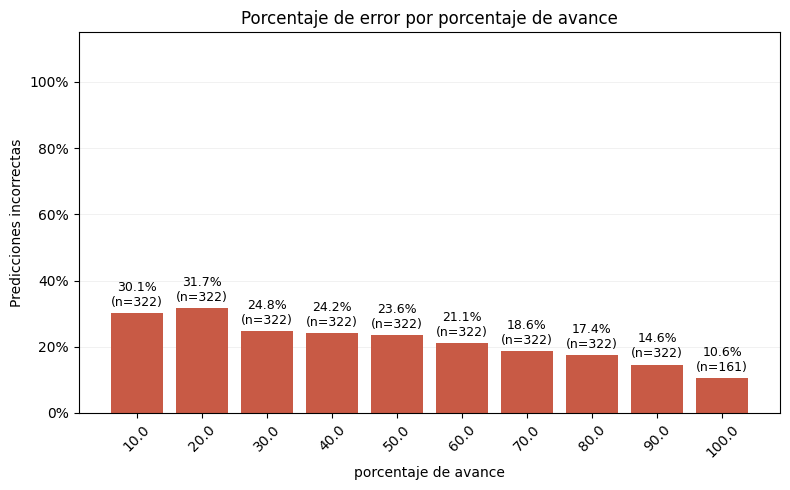

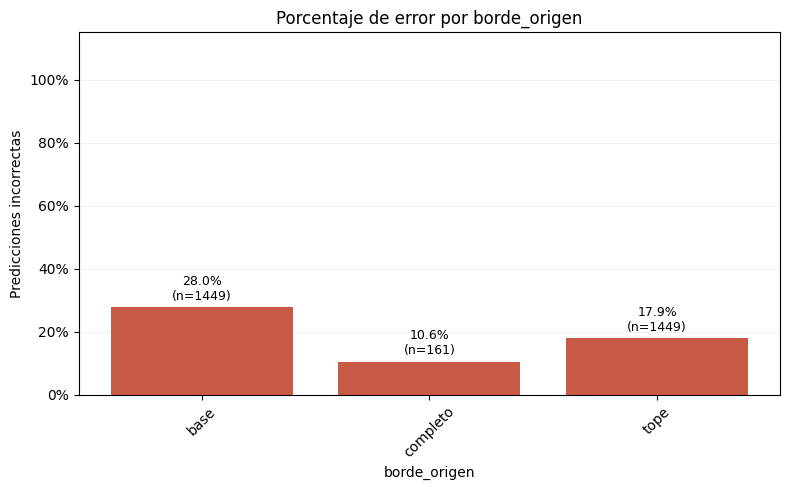

In [9]:
error_por_avance = graficar_error_por_grupo(
    tabla, "porcentaje_avance", "porcentaje de avance"
)
error_por_borde_origen = graficar_error_por_grupo(tabla, "borde_origen", "borde_origen")